In [1]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import scipy
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [2]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "legend.fontsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [3]:

def add_peak(ax, x, text, y_text, y_line_top=200):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 3, y_text),
        rotation=90,
        fontsize=11
    )

In [4]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )

In [5]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [6]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, counts



In [7]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [8]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, total_counts, total_time

# START OF THE ANALYSIS


In [9]:
FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 4.179423e-01,
            "b": 1.2696e-01,
            "c": 1.514025e-08,
        },
    },
}

In [10]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.42


BACKGROUND_PEAKS = {

    "²⁰⁸Tl": {"E": 860.45, "N": 0},
    "⁸⁴Rb":  {"E": 881.6,  "N": 0},
    "⁸⁸Y":   {"E": 898,    "N": 0},
    "²²⁸Ac": {"E": 911.204, "N": 0}
}

SIGNAL = {
    "mu": 871,
    "roi": (840, 920),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [11]:
# ============================================================
# MAIN DATA PREPARATION
# ============================================================
BINS = np.arange(
    ENERGY_RANGE[0],
    ENERGY_RANGE[1] + BIN_WIDTH,
    BIN_WIDTH
)

E_tot, Ntot, t_tot = build_total_spectrum(FILES, BINS)

print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)


Total counts = 42047 in 136.9 days


In [12]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

In [13]:

# ============================================================
# DATI
# ============================================================

E = np.asarray(E_roi, dtype=float)

E_LOW = float(np.min(E))
E_HIGH = float(np.max(E))

ROI_WIDTH = E_HIGH - E_LOW
#N_EVENTS = len(E)
N_EVENTS = sum(counts_roi)

print("ROI:")
print("  E_LOW      =", E_LOW)
print("  E_HIGH     =", E_HIGH)
print("  ROI_WIDTH  =", ROI_WIDTH)
print("  N events   =", N_EVENTS)



ROI:
  E_LOW      = 840.21
  E_HIGH     = 919.5899999999999
  ROI_WIDTH  = 79.37999999999988
  N events   = 713.0


In [14]:
E = np.repeat(E_roi, counts_roi.astype(int))

In [15]:
with pm.Model() as model:

    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================

    A_bg_list = []
    mu_bg_list = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        # Numero di eventi del background peak
        # DENTRO LA ROI
        A = pm.HalfNormal(
            f"A_{name}",
            sigma=max(N_EVENTS, 10)
        )

        # Centro del picco
        mu = pm.Normal(
            f"mu_{name}",
            mu=fit["E"],
            sigma=0.5
        )

        A_bg_list.append(A)
        mu_bg_list.append(mu)

    A_bg = pt.stack(A_bg_list)
    mu_bg = pt.stack(mu_bg_list)


    # ========================================================
    # SIGNAL
    # ========================================================

    # Eventi di segnale DENTRO LA ROI
    A_signal = pm.HalfNormal(
        "A_signal",
        sigma=max(N_EVENTS, 10)
    )

    # Posizione del segnale
    mu_signal = pm.Normal(
        "mu_signal",
        mu=SIGNAL["mu"],
        sigma=0.2
    )

    # Risoluzione del segnale
    sigma_signal = sigma_fun(mu_signal)


    # ========================================================
    # FLAT BACKGROUND
    # ========================================================

    # Eventi / energia
    Q = pm.HalfNormal(
        "Q",
        sigma=max(
            np.mean(counts_roi) / BIN_WIDTH,
            1e-3
        )
    )


    # ========================================================
    # GAUSSIANA TRONCATA/NORMALIZZATA SULLA ROI
    # ========================================================
    #
    # Usiamo la CDF della normale per calcolare:
    #
    # integral(E_LOW, E_HIGH) Gaussian(E) dE
    #
    # In questo modo l'integrale della PDF sulla ROI = 1.
    #
    # Per evitare problemi numerici usiamo erf.
    # ========================================================

    sqrt2 = pt.sqrt(2.0)


    # --------------------------------------------------------
    # SIGNAL
    # --------------------------------------------------------

    signal_z_high = (
        (E_HIGH - mu_signal)
        / (sigma_signal * sqrt2)
    )

    signal_z_low = (
        (E_LOW - mu_signal)
        / (sigma_signal * sqrt2)
    )

    signal_fraction = 0.5 * (
        1.0 + pt.erf(signal_z_high)
    ) - 0.5 * (
        1.0 + pt.erf(signal_z_low)
    )

    signal_pdf = (
        pt.exp(
            -0.5
            * ((E - mu_signal) / sigma_signal) ** 2
        )
        /
        (
            sigma_signal
            * pt.sqrt(2.0 * np.pi)
        )
    )

    # PDF normalizzata sulla ROI
    signal_pdf_roi = (
        signal_pdf / signal_fraction
    )

    signal_intensity = (
        A_signal
        * signal_pdf_roi
    )


    # ========================================================
    # BACKGROUND GAUSSIANS
    # ========================================================

    bg_intensity = pt.zeros_like(E)

    N_bg_terms = []

    for i, name in enumerate(BACKGROUND_PEAKS):

        # Risoluzione corrispondente all'energia
        # del background peak
        sigma_bg = sigma_fun(mu_bg[i])


        # ----------------------------------------------------
        # Integrale della gaussiana sulla ROI
        # ----------------------------------------------------

        bg_z_high = (
            (E_HIGH - mu_bg[i])
            / (sigma_bg * sqrt2)
        )

        bg_z_low = (
            (E_LOW - mu_bg[i])
            / (sigma_bg * sqrt2)
        )

        bg_fraction = 0.5 * (
            1.0 + pt.erf(bg_z_high)
        ) - 0.5 * (
            1.0 + pt.erf(bg_z_low)
        )


        # ----------------------------------------------------
        # PDF gaussiana
        # ----------------------------------------------------

        bg_pdf = (
            pt.exp(
                -0.5
                * ((E - mu_bg[i]) / sigma_bg) ** 2
            )
            /
            (
                sigma_bg
                * pt.sqrt(2.0 * np.pi)
            )
        )


        # Normalizzazione sulla ROI
        bg_pdf_roi = (
            bg_pdf / bg_fraction
        )


        # Intensità del background peak
        bg_intensity += (
            A_bg[i]
            * bg_pdf_roi
        )


        # Poiché A_bg è già definito come
        # numero di eventi dentro la ROI:
        N_bg_terms.append(A_bg[i])


    N_bg = pt.sum(pt.stack(N_bg_terms))


    # ========================================================
    # FLAT BACKGROUND
    # ========================================================

    flat_intensity = Q

    N_flat = Q * ROI_WIDTH


    # ========================================================
    # TOTAL INTENSITY
    # ========================================================

    lambda_E = (
        signal_intensity
        + bg_intensity
        + flat_intensity
    )


    # ========================================================
    # EXPECTED NUMBER OF EVENTS
    # ========================================================

    N_expected = (
        A_signal
        + N_bg
        + N_flat
    )


    # ========================================================
    # PROTEZIONE NUMERICA
    # ========================================================

    lambda_E_safe = pt.maximum(
        lambda_E,
        1e-12
    )


    # ========================================================
    # EXTENDED UNBINNED LOG-LIKELIHOOD
    # ========================================================

    logL = (
        -N_expected
        + pt.sum(
            pt.log(lambda_E_safe)
        )
    )


    pm.Potential(
        "likelihood",
        logL
    )


    # ========================================================
    # SAMPLING
    # ========================================================

    trace = pm.sample(
        draws=2000,
        tune=4000,
        chains=4,
        cores=min(
            4,
            multiprocessing.cpu_count()
        ),
        target_accept=0.95,
        init="jitter+adapt_diag",
        random_seed=42,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
/home/ritaferi/pymc-env/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²⁰⁸Tl, mu_²⁰⁸Tl, A_⁸⁴Rb, mu_⁸⁴Rb, A_⁸⁸Y, mu_⁸⁸Y, A_²²⁸Ac, mu_²²⁸Ac, A_signal, mu_signal, Q]


Output()

Sampling 4 chains for 4_000 tune and 2_000 draw iterations (16_000 + 8_000 draws total) took 22 seconds.


In [16]:
summary = az.summary(trace, round_to=4)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_²⁰⁸Tl,860.7942,0.2797,860.2802,861.3328,0.0028,0.0036,9889.8444,5779.2411,1.0010
mu_⁸⁴Rb,881.4815,0.3838,880.8032,882.2557,0.0039,0.0050,9654.2487,5841.4829,1.0026
mu_⁸⁸Y,898.1196,0.0975,897.9396,898.3033,0.0010,0.0012,10214.1259,5007.2334,1.0016
mu_²²⁸Ac,911.1329,0.1329,910.8820,911.3899,0.0014,0.0016,9591.7745,5687.6629,0.9999
mu_signal,871.0257,0.1987,870.6669,871.4130,0.0022,0.0025,8593.1753,5603.3472,1.0008
A_²⁰⁸Tl,22.3536,6.6748,10.2997,35.4102,0.0656,0.0817,9504.8547,4534.1686,1.0003
A_⁸⁴Rb,8.0931,4.8245,0.0132,16.1753,0.0579,0.0520,5095.0999,2875.6289,1.0006
A_⁸⁸Y,146.5199,13.2627,121.7938,171.1624,0.1312,0.1473,10130.7445,5594.5023,1.0000
A_²²⁸Ac,91.6011,11.0001,71.1057,112.6272,0.1118,0.1411,9577.0930,5318.3804,1.0001
A_signal,4.3285,3.3706,0.0015,10.4409,0.0346,0.0422,6431.0169,3746.5945,1.0004


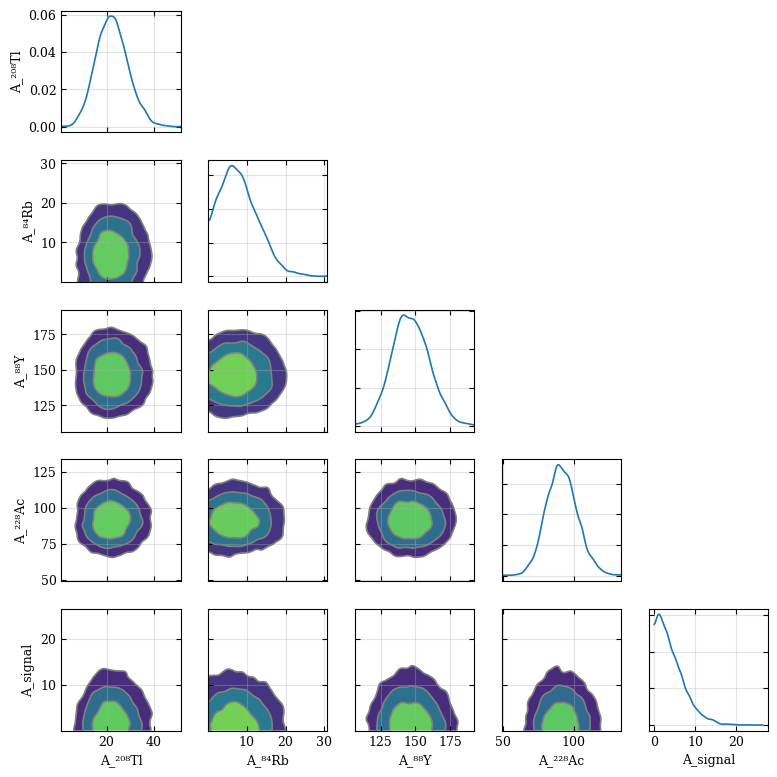

In [17]:
A_vars = [v for v in trace.posterior.data_vars if v.startswith("A_")]

axes = az.plot_pair(
    trace,
    var_names=A_vars,
    kind="kde",
    marginals=True,
    figsize=(8, 8),
    textsize=9,
)

for ax in axes.flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.show()

In [18]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
signal_samples = trace.posterior["A_signal"].values.flatten()

N_signal_90 = np.percentile(signal_samples, 90)
N_signal_95 = np.percentile(signal_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on signal counts : {N_signal_90:.3f}")
print(f"95% upper limit on signal counts : {N_signal_95:.3f}")
print("=" * 60)


90% upper limit on signal counts : 8.918
95% upper limit on signal counts : 10.860


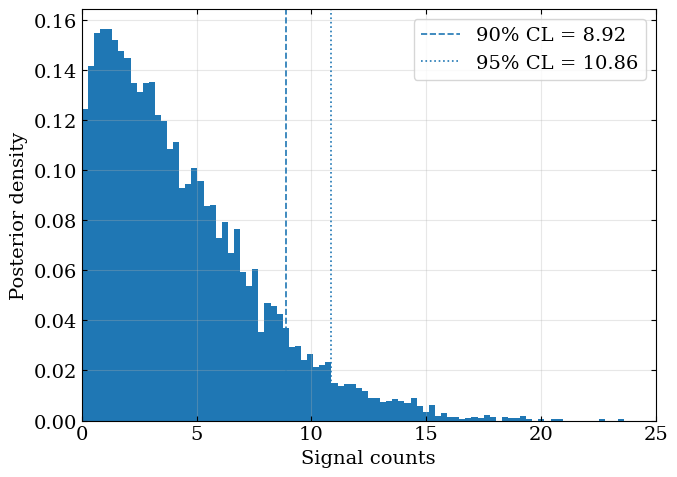

In [19]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(7, 5))

plt.hist(signal_samples, bins=100, density=True)

plt.axvline(
    N_signal_90,
    linestyle="--",
    label=f"90% CL = {N_signal_90:.2f}",
)

plt.axvline(
    N_signal_95,
    linestyle=":",
    label=f"95% CL = {N_signal_95:.2f}",
)

plt.xlabel("Signal counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.xlim(0,25)
plt.legend()

plt.tight_layout()
plt.show()



In [20]:
# posterior extraction
# ============================================================
# POSTERIOR EXTRACTION
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

idata = trace
posterior = idata.posterior

Q_s = posterior["Q"].values.reshape(-1)

A_signal_s = posterior["A_signal"].values.reshape(-1)
mu_signal_s = posterior["mu_signal"].values.reshape(-1)

A_bg_s = {
    name: posterior[f"A_{name}"].values.reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"].values.reshape(-1)
    for name in background_names
}

In [21]:
print("\nPOSTERIOR SAMPLES")
print("N samples =", len(A_signal_s))

print("\nSignal:")
print("A_signal =", np.mean(A_signal_s), "+/-", np.std(A_signal_s))
print("mu_signal =", np.mean(mu_signal_s), "+/-", np.std(mu_signal_s))

print("\nFlat background:")
print("Q =", np.mean(Q_s), "+/-", np.std(Q_s))

for name in background_names:
    print(f"\nBackground: {name}")
    print("A =", np.mean(A_bg_s[name]), "+/-", np.std(A_bg_s[name]))
    print("mu =", np.mean(mu_bg_s[name]), "+/-", np.std(mu_bg_s[name]))


POSTERIOR SAMPLES
N samples = 8000

Signal:
A_signal = 4.328522902923456 +/- 3.3703572932535857
mu_signal = 871.0257200236889 +/- 0.19866489776978902

Flat background:
Q = 5.61226538944157 +/- 0.30190977079031345

Background: ²⁰⁸Tl
A = 22.353571209199792 +/- 6.674386101364818
mu = 860.7941761770796 +/- 0.2796648667888765

Background: ⁸⁴Rb
A = 8.09314036647201 +/- 4.824188552849406
mu = 881.4814922168969 +/- 0.38376731085564153

Background: ⁸⁸Y
A = 146.51993051447946 +/- 13.26191104309492
mu = 898.119631376699 +/- 0.097541835101141

Background: ²²⁸Ac
A = 91.60109633519268 +/- 10.999382226908494
mu = 911.1328869613853 +/- 0.13290224417620064


# FINAL LIMIT-

In [22]:

# Dati campione
m_sample = 551.3        # massa ZrO2 in grammi
Mr_sample = 123.22      # massa molare ZrO2 [g/mol]
N_A = 6.022e23          # numero di Avogadro
eff_94Zr = 0.0294935    # efficienza di rivelazione
i_a_94Zr = 0.1738       # abbondanza isotopica
t_live =    t_tot/(60*60*24*365)             # 90 giorni in anni

N_nuclei = (m_sample * i_a_94Zr / Mr_sample) * N_A


In [23]:
N_signal_90

np.float64(8.918100049354187)

In [24]:
# Numero di nuclei 96Zr nel campione
N_nuclei = (m_sample * i_a_94Zr / Mr_sample) * N_A

percentile = 90
T_half_limit = (np.log(2) * N_nuclei * eff_94Zr * t_live) /N_signal_90
print(f"T1/2 > {T_half_limit:.2e} yrs at {percentile}%")

T1/2 > 4.03e+20 yrs at 90%
